# Analisis Kondisi Armada Operasional Damkar DKI Jakarta
## Exploratory Data Analysis (EDA) dan Klasifikasi Random Forest

**Proyek Akhir Data Science 2026/2027 — Kelompok 50 (Next Level)**  
Program Studi Informatika, Fakultas Teknik Industri, Universitas Pembangunan Nasional “Veteran” Yogyakarta.

**Anggota kelompok**
1. Dwirizki Adithya Putra — 123240021
2. Satya Dio Putranto — 123240121
3. Sebastian Alvaro Huller — 123240162
4. Paksi Dwirangga — 123240172

Notebook ini membahas data armada kendaraan pemadam kebakaran dan penyelamatan DKI Jakarta. Analisis dimulai dari pemahaman data, pemeriksaan pola, penyiapan fitur, hingga pengujian model klasifikasi. Random Forest digunakan sebagai model utama, sementara SVM dengan kernel linear dipakai untuk melihat perbandingan hasil.

> **Ruang lingkup:** kolom `Kondisi` berisi status yang tercatat pada dataset periode 2025. Hasil analisis tidak menggambarkan kesiapan kendaraan secara langsung pada saat ini dan tidak dapat menggantikan pemeriksaan teknis di lapangan.


## Daftar isi notebook

| Tahap | Pembahasan |
|---|---|
| 1. Business Understanding | Latar belakang, rumusan masalah, tujuan, metode, ukuran evaluasi, dan batasan |
| 2. Data Gathering | Asal data, proses pemuatan, penjelasan kolom, serta alasan pemilihan |
| 3. EDA | Struktur data, statistik ringkas, distribusi kondisi, dan pola berdasarkan karakteristik armada |
| 4. Cleaning & Preprocessing | Pemeriksaan kualitas, perapian nilai, penanganan data kosong, dan encoding |
| 5. Feature Selection & Modelling | Penentuan fitur, pembagian data, dan pembangunan model |
| 6. Evaluation | Perbandingan hasil, confusion matrix, dan feature importance |
| 7. Conclusion | Rangkuman temuan, makna hasil, saran, serta keterbatasan |

Analisis berfokus pada klasifikasi karena kolom `Kondisi` menyediakan dua label, yaitu `BAIK` dan `RUSAK`. EDA digunakan untuk memahami karakteristik dataset sebelum model dibangun. Sejumlah pendekatan lain tidak diterapkan karena tidak sesuai dengan tujuan analisis ini.


# BAGIAN 1 — BUSINESS UNDERSTANDING

## 1.1 Latar belakang dan masalah

Ketersediaan armada menjadi salah satu unsur penting dalam pelayanan pemadam kebakaran dan penyelamatan. Informasi mengenai jenis kendaraan, fungsi, wilayah penempatan, serta kondisi yang tercatat dapat membantu memberikan gambaran awal tentang komposisi armada.

Satu Data Jakarta menyediakan dataset kendaraan operasional yang memuat informasi tersebut. Data ini dapat ditelaah untuk melihat bagaimana kondisi kendaraan tersebar dan apakah karakteristik yang tersedia berkaitan dengan label kondisi. Perlu diperhatikan bahwa dataset merupakan catatan administratif untuk periode tertentu, bukan pemantauan kendaraan secara langsung.

## 1.2 Pertanyaan analisis

1. Bagaimana perbandingan jumlah kendaraan berlabel `BAIK` dan `RUSAK`?
2. Bagaimana sebaran kendaraan dan kondisi yang tercatat jika dilihat dari wilayah, jenis, klasifikasi, dan fungsi?
3. Seberapa baik fitur yang tersedia membantu model mengenali label kondisi pada data yang belum digunakan saat pelatihan?
4. Bagaimana perbedaan hasil Random Forest dan SVM kernel linear, khususnya dalam mengenali kelas `RUSAK`?
5. Fitur apa yang paling berpengaruh dalam pemisahan kelas pada model Random Forest?

## 1.3 Tujuan dan metode

Pekerjaan ini bertujuan menggambarkan karakteristik armada melalui EDA, menyiapkan data agar dapat dianalisis, dan menguji model untuk mengelompokkan catatan kendaraan ke dalam label `BAIK` atau `RUSAK`. Random Forest dipilih sebagai pendekatan utama, kemudian hasilnya dibandingkan dengan SVM kernel linear. Perbandingan dilakukan pada bagian data uji yang sama agar hasil kedua model dapat dibaca secara seimbang.

## 1.4 Metrik evaluasi

- **Accuracy:** persentase seluruh prediksi yang sesuai dengan label sebenarnya.
- **Precision kelas RUSAK:** bagian prediksi `RUSAK` yang memang berlabel `RUSAK`.
- **Recall kelas RUSAK:** bagian dari seluruh catatan `RUSAK` yang berhasil dikenali model.
- **F1-score kelas RUSAK:** ukuran yang menggabungkan precision dan recall untuk kelas tersebut.
- **Macro-F1:** rata-rata F1 dari kedua kelas dengan bobot yang sama, sehingga kelas dengan jumlah lebih sedikit tetap diperhitungkan.

## 1.5 Batasan awal

Dataset hanya menggambarkan periode 2025. Informasi seperti tanggal pemeriksaan, usia kendaraan, riwayat perawatan, jarak tempuh atau jam operasi, tingkat kerusakan, koordinat, dan catatan kejadian tidak tersedia pada berkas yang dianalisis. Oleh karena itu, hasil model hanya menunjukkan kemampuannya mengenali label dalam dataset, bukan menentukan penyebab kerusakan atau kondisi operasional kendaraan saat ini.


# BAGIAN 2 — DATA GATHERING

## 2.1 Sumber data

Data yang digunakan berasal dari portal resmi **Satu Data Jakarta**, dengan judul [Data Kendaraan Operasional Penanggulangan Kebakaran dan Penyelamatan](https://satudata.jakarta.go.id/open-data/detail?kategori=dataset&page_url=data-kendaraan-operasional-penanggulangan-kebakaran-dan-penyelamatan&data_no=1).

Pemeriksaan sumber dilakukan pada 20 November 2026. Salinan yang diperiksa memuat 1.153 baris dan 10 kolom. Berkas sumber berekstensi `.xls`, tetapi isinya terbaca sebagai tabel HTML sehingga pembacaan awal dilakukan menggunakan `pandas.read_html`.

**Lisensi:** Halaman umum Satu Data Jakarta menyatakan bahwa data pada portal dapat dimanfaatkan dan digunakan kembali. Lisensi dataset ini bersifat **Terbuka** dan telah berhasil diverifikasi melalui metadata dataset yang dapat diakses. Sumber data tetap dicantumkan sebagai bentuk atribusi. Berkas yang digunakan dalam analisis merupakan salinan sanitasi yang tidak menyertakan kolom `plat_nomor`.

## 2.2 Pemuatan dataset

Notebook membaca berkas CSV hasil sanitasi yang berada di folder `data/processed`. Kolom `plat_nomor` tidak disertakan karena merupakan pengenal kendaraan dan tidak dibutuhkan sebagai variabel untuk membangun model. Rangkuman pemeriksaan terhadap berkas sumber disimpan terpisah pada `data/source_audit.json`.


In [33]:
from pathlib import Path
import json
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay
)

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
RANDOM_STATE = 42
ROOT = Path.cwd()
# Mendukung eksekusi dari root repository maupun dari folder notebooks.
if not (ROOT / "data").exists() and (ROOT.parent / "data").exists():
    ROOT = ROOT.parent
DATA_PATH = ROOT / "data" / "processed" / "kendaraan_2025_sanitized.csv"
AUDIT_PATH = ROOT / "data" / "source_audit.json"
OUTPUT_DIR = ROOT / "outputs"
FIGURE_DIR = OUTPUT_DIR / "figures"
OUTPUT_DIR.mkdir(exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

if not DATA_PATH.exists():
    raise FileNotFoundError(f"Dataset tidak ditemukan: {DATA_PATH}. Jalankan notebook dari root proyek atau folder notebooks.")

df_source = pd.read_csv(DATA_PATH)
source_audit = json.loads(AUDIT_PATH.read_text(encoding="utf-8")) if AUDIT_PATH.exists() else {}
print("Lokasi dataset:", DATA_PATH)
print("Ukuran dataset sanitasi:", df_source.shape)
display(df_source.head())

Lokasi dataset: d:\Documents\UPN Veteran Yogyakarta\Semester 5\Data Science\50_IF-E_NextLevel\data\processed\kendaraan_2025_sanitized.csv
Ukuran dataset sanitasi: (1153, 9)


,periode_data,wilayah,kecamatan,kelurahan,jenis_kendaraan,klasifikasi,fungsi,penempatan,Kondisi
0,2025,KOTA ADM. JAKARTA UTARA,CILINCING,SEMPER BARAT,MOTOR PEMADAM KEBAKARAN DAN PENYELAMATAN,SEPEDA MOTOR,OPERASIONAL UMUM,KANTOR SUDIN JAKARTA UTARA,BAIK
1,2025,KOTA ADM. JAKARTA UTARA,CILINCING,SEMPER BARAT,MOTOR PEMADAM KEBAKARAN DAN PENYELAMATAN,SEPEDA MOTOR,OPERASIONAL UMUM,KANTOR SUDIN JAKARTA UTARA,BAIK
2,2025,KOTA ADM. JAKARTA UTARA,CILINCING,SEMPER BARAT,MOTOR PEMADAM KEBAKARAN DAN PENYELAMATAN,SEPEDA MOTOR,OPERASIONAL UMUM,KANTOR SUDIN JAKARTA UTARA,BAIK
3,2025,KOTA ADM. JAKARTA UTARA,CILINCING,SEMPER BARAT,MOTOR PEMADAM KEBAKARAN DAN PENYELAMATAN,SEPEDA MOTOR,OPERASIONAL UMUM,KANTOR SUDIN JAKARTA UTARA,BAIK
4,2025,KOTA ADM. JAKARTA UTARA,TANJUNG PRIOK,SUNTER JAYA,MOTOR PEMADAM KEBAKARAN DAN PENYELAMATAN,SEPEDA MOTOR,OPERASIONAL UMUM,POS SUNTER JAYA (KANGKUNGAN),BAIK


## 2.3 Gambaran dataset dan data dictionary

Setiap baris pada dataset menunjukkan satu catatan kendaraan dalam inventaris sumber. Kolom `plat_nomor` tidak disertakan pada berkas yang dipakai untuk analisis.

kolom di bawah disusun dengan melihat nama atribut dan nilai yang muncul di dalam data, Karena metadata resmi tidak menyediakan definisi yang lebih rinci.


In [34]:
data_dictionary =  pd.DataFrame ([
    ["periode_data", "Periode/tahun pencatatan data", "Numerik/kategori", "Dikeluarkan dari model karena hanya satu nilai pada snapshot ini"],
    ["wilayah", "Wilayah administratif kota/kabupaten", "Kategorikal nominal", "Digunakan sebagai fitur"],
    ["kecamatan", "Nama kecamatan", "Kategorikal nominal", "Tidak digunakan; rincian wilayah berhierarki dan berpotensi redundan"],
    ["kelurahan", "Nama kelurahan", "Kategorikal nominal", "Tidak digunakan; kategori lebih rinci dan cardinality lebih tinggi"],
    ["jenis_kendaraan", "Jenis/nama kendaraan operasional", "Kategorikal nominal", "Digunakan sebagai fitur"],
    ["klasifikasi", "Klasifikasi kendaraan", "Kategorikal nominal", "Digunakan sebagai fitur"],
    ["fungsi", "Fungsi kendaraan sebagaimana tercatat", "Kategorikal nominal", "Digunakan sebagai fitur"],
    ["penempatan", "Lokasi/unit penempatan kendaraan", "Kategorikal nominal", "Tidak digunakan; cardinality tinggi dan berpotensi menghafal lokasi"],
    ["Kondisi", "Label kondisi kendaraan: BAIK/RUSAK", "Target kategorikal", "Target klasifikasi"],
], columns=["kolom", "arti_operasional", "tipe", "keputusan_analisis"])
display(data_dictionary)

,kolom,arti_operasional,tipe,keputusan_analisis
0,periode_data,Periode/tahun pencatatan data,Numerik/kategori,Dikeluarkan dari model karena hanya satu nilai...
1,wilayah,Wilayah administratif kota/kabupaten,Kategorikal nominal,Digunakan sebagai fitur
2,kecamatan,Nama kecamatan,Kategorikal nominal,Tidak digunakan; rincian wilayah berhierarki d...
3,kelurahan,Nama kelurahan,Kategorikal nominal,Tidak digunakan; kategori lebih rinci dan card...
4,jenis_kendaraan,Jenis/nama kendaraan operasional,Kategorikal nominal,Digunakan sebagai fitur
5,klasifikasi,Klasifikasi kendaraan,Kategorikal nominal,Digunakan sebagai fitur
6,fungsi,Fungsi kendaraan sebagaimana tercatat,Kategorikal nominal,Digunakan sebagai fitur
7,penempatan,Lokasi/unit penempatan kendaraan,Kategorikal nominal,Tidak digunakan; cardinality tinggi dan berpot...
8,Kondisi,Label kondisi kendaraan: BAIK/RUSAK,Target kategorikal,Target klasifikasi


## 2.4 Alasan pemilihan dataset

Dataset ini dipilih karena diterbitkan melalui portal data pemerintah daerah dan berkaitan langsung dengan layanan pemadam kebakaran serta penyelamatan. Jumlah datanya juga memadai untuk analisis, dengan 1.153 catatan dan sejumlah atribut yang dapat digunakan untuk menggambarkan karakteristik kendaraan. Selain itu, tersedia kolom `Kondisi` yang berisi label `BAIK` dan `RUSAK`, sehingga sesuai untuk percobaan klasifikasi.

Pada berkas sumber ditemukan lima nilai kosong di kolom `plat_nomor`. Kolom tersebut tidak dipakai dalam pemodelan karena hanya berfungsi sebagai pengenal kendaraan, sehingga dihilangkan dari salinan dataset yang dianalisis.


In [35]:
print("Audit sumber asli (ringkasan saat sanitasi):")
for key in ["source_rows", "source_columns", "source_missing_total", "source_exact_duplicate_rows", "license_status"]:
    print(f"{key}: {source_audit.get(key, 'tidak tersedia')}")
print("\nMissing value pada CSV sanitasi:")
display(df_source.isna().sum().to_frame("jumlah_missing"))

Audit sumber asli (ringkasan saat sanitasi):
source_rows: 1153
source_columns: 10
source_missing_total: 5
source_exact_duplicate_rows: 0
license_status: Terbuka; berhasil diverifikasi pada metadata dataset yang dapat diakses. Halaman umum Satu Data Jakarta menyatakan bahwa data pada portal dapat dimanfaatkan dan digunakan kembali.

Missing value pada CSV sanitasi:


,jumlah_missing
periode_data,0
wilayah,0
kecamatan,0
kelurahan,0
jenis_kendaraan,0
klasifikasi,0
fungsi,0
penempatan,0
Kondisi,0


# BAGIAN 3 — EXPLORATORY DATA ANALYSIS (EDA)

## 3.1 Pemeriksaan struktur dan statistik deskriptif

Tahap awal dilakukan dengan memeriksa tipe data, jumlah nilai yang terisi, nilai unik, serta frekuensi setiap kategori. Pemeriksaan ini membantu mengenali bentuk dataset sebelum analisis lebih lanjut. Karena sebagian besar atribut berupa kategori, jumlah dan proporsi tiap kategori lebih mudah digunakan untuk membaca pola dibandingkan ukuran statistik seperti rata-rata atau standar deviasi.


In [36]:
print("Informasi struktur dataset:")
df_source.info()
print("\nStatistik deskriptif seluruh kolom:")
display(df_source.describe(include="all").T)
print("\nJumlah kategori unik per kolom:")
display(df_source.nunique(dropna=True).to_frame("jumlah_kategori_unik"))

Informasi struktur dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1153 entries, 0 to 1152
Data columns (total 9 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   periode_data     1153 non-null   int64 
 1   wilayah          1153 non-null   object
 2   kecamatan        1153 non-null   object
 3   kelurahan        1153 non-null   object
 4   jenis_kendaraan  1153 non-null   object
 5   klasifikasi      1153 non-null   object
 6   fungsi           1153 non-null   object
 7   penempatan       1153 non-null   object
 8   Kondisi          1153 non-null   object
dtypes: int64(1), object(8)
memory usage: 81.2+ KB

Statistik deskriptif seluruh kolom:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
periode_data,1153.0,NaN,NaN,NaN,2025.0,0.0,2025.0,2025.0,2025.0,2025.0,2025.0
wilayah,1153,6,KOTA ADM. JAKARTA TIMUR,250,NaN,NaN,NaN,NaN,NaN,NaN,NaN
kecamatan,1153,44,CILINCING,104,NaN,NaN,NaN,NaN,NaN,NaN,NaN
kelurahan,1153,138,SEMPER BARAT,89,NaN,NaN,NaN,NaN,NaN,NaN,NaN
jenis_kendaraan,1153,36,MOTOR PEMADAM KEBAKARAN DAN PENYELAMATAN,470,NaN,NaN,NaN,NaN,NaN,NaN,NaN
klasifikasi,1153,8,SEPEDA MOTOR,470,NaN,NaN,NaN,NaN,NaN,NaN,NaN
fungsi,1153,40,PEMADAMAN KEBAKARAN,280,NaN,NaN,NaN,NaN,NaN,NaN,NaN
penempatan,1153,179,KANTOR SUDIN JAKARTA UTARA,89,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Kondisi,1153,2,BAIK,984,NaN,NaN,NaN,NaN,NaN,NaN,NaN



Jumlah kategori unik per kolom:


,jumlah_kategori_unik
periode_data,1
wilayah,6
kecamatan,44
kelurahan,138
jenis_kendaraan,36
klasifikasi,8
fungsi,40
penempatan,179
Kondisi,2


## 3.2 Distribusi kondisi kendaraan

Bagian ini memperlihatkan jumlah dan persentase kendaraan berdasarkan label `BAIK` dan `RUSAK`. Perbandingan tersebut penting karena jumlah kedua kelas tidak seimbang. Kondisi ini perlu diperhatikan ketika membaca hasil model, sebab model dapat terlihat memiliki accuracy tinggi meskipun belum cukup baik mengenali kelas yang jumlahnya lebih sedikit.


,jumlah,persentase
Kondisi,,
BAIK,984,85.34
RUSAK,169,14.66


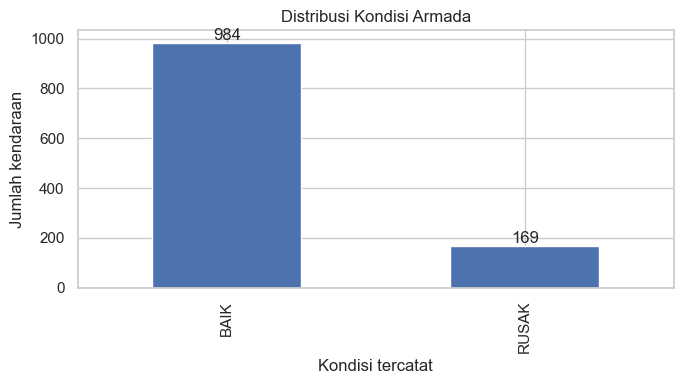

In [37]:
condition_counts = df_source["Kondisi"].value_counts(dropna=False)
condition_pct = df_source["Kondisi"].value_counts(normalize=True, dropna=False).mul(100)
condition_summary = pd.DataFrame({"jumlah": condition_counts, "persentase": condition_pct.round(2)})
display(condition_summary)
fig, ax = plt.subplots(figsize=(7, 4))
condition_counts.plot(kind="bar", ax=ax)
ax.set(title="Distribusi Kondisi Armada", xlabel="Kondisi tercatat", ylabel="Jumlah kendaraan")
for container in ax.containers:
    ax.bar_label(container)
plt.tight_layout(); plt.savefig(FIGURE_DIR / "01_distribusi_kondisi.png", dpi=160); plt.show()

**Interpretasi:** tabel dan grafik memperlihatkan bahwa catatan berlabel `BAIK` lebih banyak dibandingkan `RUSAK`. Ketimpangan jumlah ini membuat accuracy saja belum cukup untuk menilai model. Perhatian juga perlu diberikan pada recall dan F1-score kelas `RUSAK` agar terlihat seberapa banyak catatan pada kelas tersebut yang berhasil dikenali.


## 3.3 Komposisi armada menurut wilayah

Jumlah catatan kendaraan pada setiap wilayah ditampilkan untuk melihat sebaran armada. Grafik berikutnya membandingkan persentase kondisi di dalam masing-masing wilayah. Kedua tampilan ini perlu dibaca bersama karena jumlah kendaraan yang besar tidak selalu berarti proporsi kerusakannya juga tinggi.


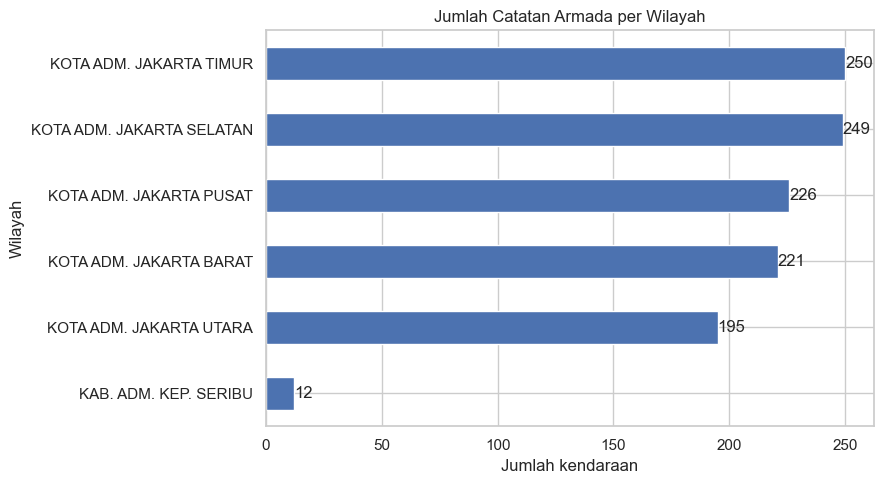

Kondisi,BAIK,RUSAK
wilayah,,
KAB. ADM. KEP. SERIBU,100.00,0.00
KOTA ADM. JAKARTA SELATAN,92.77,7.23
KOTA ADM. JAKARTA BARAT,88.24,11.76
KOTA ADM. JAKARTA PUSAT,84.51,15.49
KOTA ADM. JAKARTA UTARA,82.56,17.44
KOTA ADM. JAKARTA TIMUR,77.60,22.40


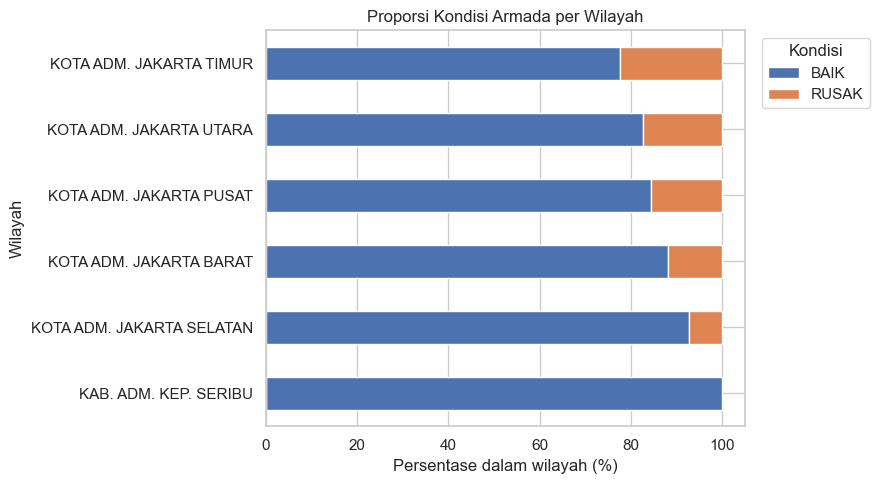

In [38]:
wilayah_count = df_source["wilayah"].value_counts().sort_values(ascending=True)
fig, ax = plt.subplots(figsize=(9, 5))
wilayah_count.plot(kind="barh", ax=ax)
ax.set(title="Jumlah Catatan Armada per Wilayah", xlabel="Jumlah kendaraan", ylabel="Wilayah")
for container in ax.containers:
    ax.bar_label(container)
plt.tight_layout(); plt.savefig(FIGURE_DIR / "02_jumlah_per_wilayah.png", dpi=160); plt.show()

wilayah_condition = pd.crosstab(df_source["wilayah"], df_source["Kondisi"], normalize="index").mul(100)
if "RUSAK" in wilayah_condition.columns:
    wilayah_condition = wilayah_condition.sort_values("RUSAK", ascending=True)
display(wilayah_condition.round(2))
ax = wilayah_condition.plot(kind="barh", stacked=True, figsize=(9, 5))
ax.set(title="Proporsi Kondisi Armada per Wilayah", xlabel="Persentase dalam wilayah (%)", ylabel="Wilayah")
ax.legend(title="Kondisi", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout(); plt.savefig(FIGURE_DIR / "03_proporsi_kondisi_wilayah.png", dpi=160, bbox_inches="tight"); plt.show()

**Interpretasi:** persentase `RUSAK` memberikan gambaran yang lebih sebanding antarwilayah daripada jumlah kasus semata. Wilayah dengan armada lebih banyak mungkin memiliki catatan `RUSAK` lebih banyak karena jumlah kendaraannya memang lebih besar. Hasil pada wilayah dengan jumlah catatan sedikit perlu dibaca secara hati-hati.


## 3.4 Komposisi menurut jenis, klasifikasi, dan fungsi

Bagian ini membandingkan jumlah kendaraan dan distribusi kondisi berdasarkan jenis kendaraan, klasifikasi, serta fungsi. Pengelompokan tersebut membantu melihat karakteristik armada yang paling banyak tercatat dan variasi label kondisi pada setiap kategori.


Kondisi,BAIK,RUSAK
jenis_kendaraan,,
KAPAL PEMADAM KEBAKARAN RESCUE BOAT 01,100.00,0.00
KAPAL PEMADAM KEBAKARAN RESCUE BOAT 06,100.00,0.00
KAPAL PEMADAM KEBAKARAN SATRIA BIRU,100.00,0.00
KAPAL PEMADAM KEBAKARAN SATRIA BIRU 01,100.00,0.00
KAPAL PEMADAM KEBAKARAN SATRIA BIRU 07,100.00,0.00
MOBIL AMBULANCE,100.00,0.00
MOBIL DEREK,100.00,0.00
MOBIL KOMANDO,100.00,0.00
MOBIL TANKI BBM,100.00,0.00


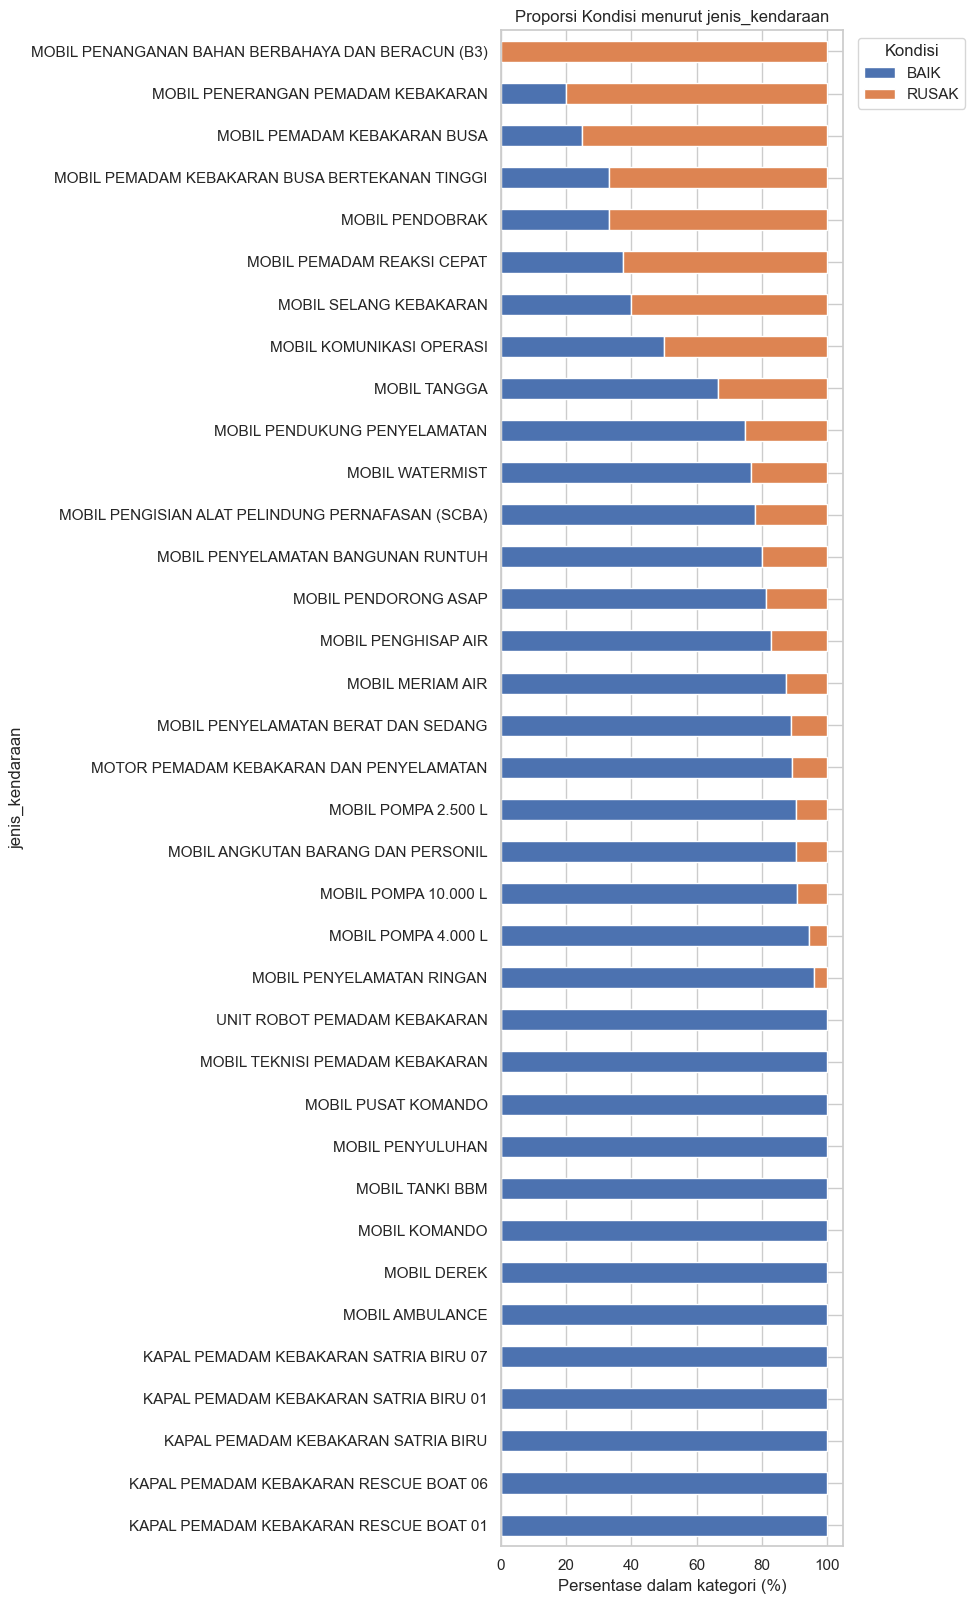

Kondisi,BAIK,RUSAK
klasifikasi,,
KAPAL,100.00,0.00
MOBIL AMBULAN,100.00,0.00
MOBIL RESCUE,90.77,9.23
KENDARAAN OPERASIONAL LAINNYA,90.70,9.30
SEPEDA MOTOR,89.36,10.64
MOBIL POMPA,89.34,10.66
MOBIL PENDUKUNG,73.33,26.67
MOBIL TANGGA,61.90,38.10


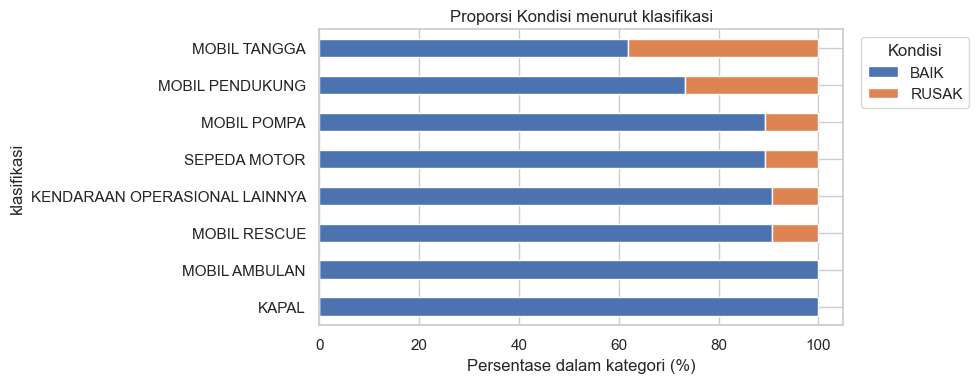

Kondisi,BAIK,RUSAK
fungsi,,
AMBULAN TRANSPORTASI,100.00,0.00
ANGKUTAN BARANG,100.00,0.00
ANGKUTAN PERSONIL,100.00,0.00
BENGKEL BERGERAK,100.00,0.00
DEREK PADA SITUASI KEDARURATAN,100.00,0.00
OPERASIONAL PETUGAS PENYULUH LAPANGAN,100.00,0.00
OPERASIONAL PEMBUKA JALAN,100.00,0.00
OPERASIONAL KHUSUS,100.00,0.00
OPERSAIONAL KASUDIN,100.00,0.00


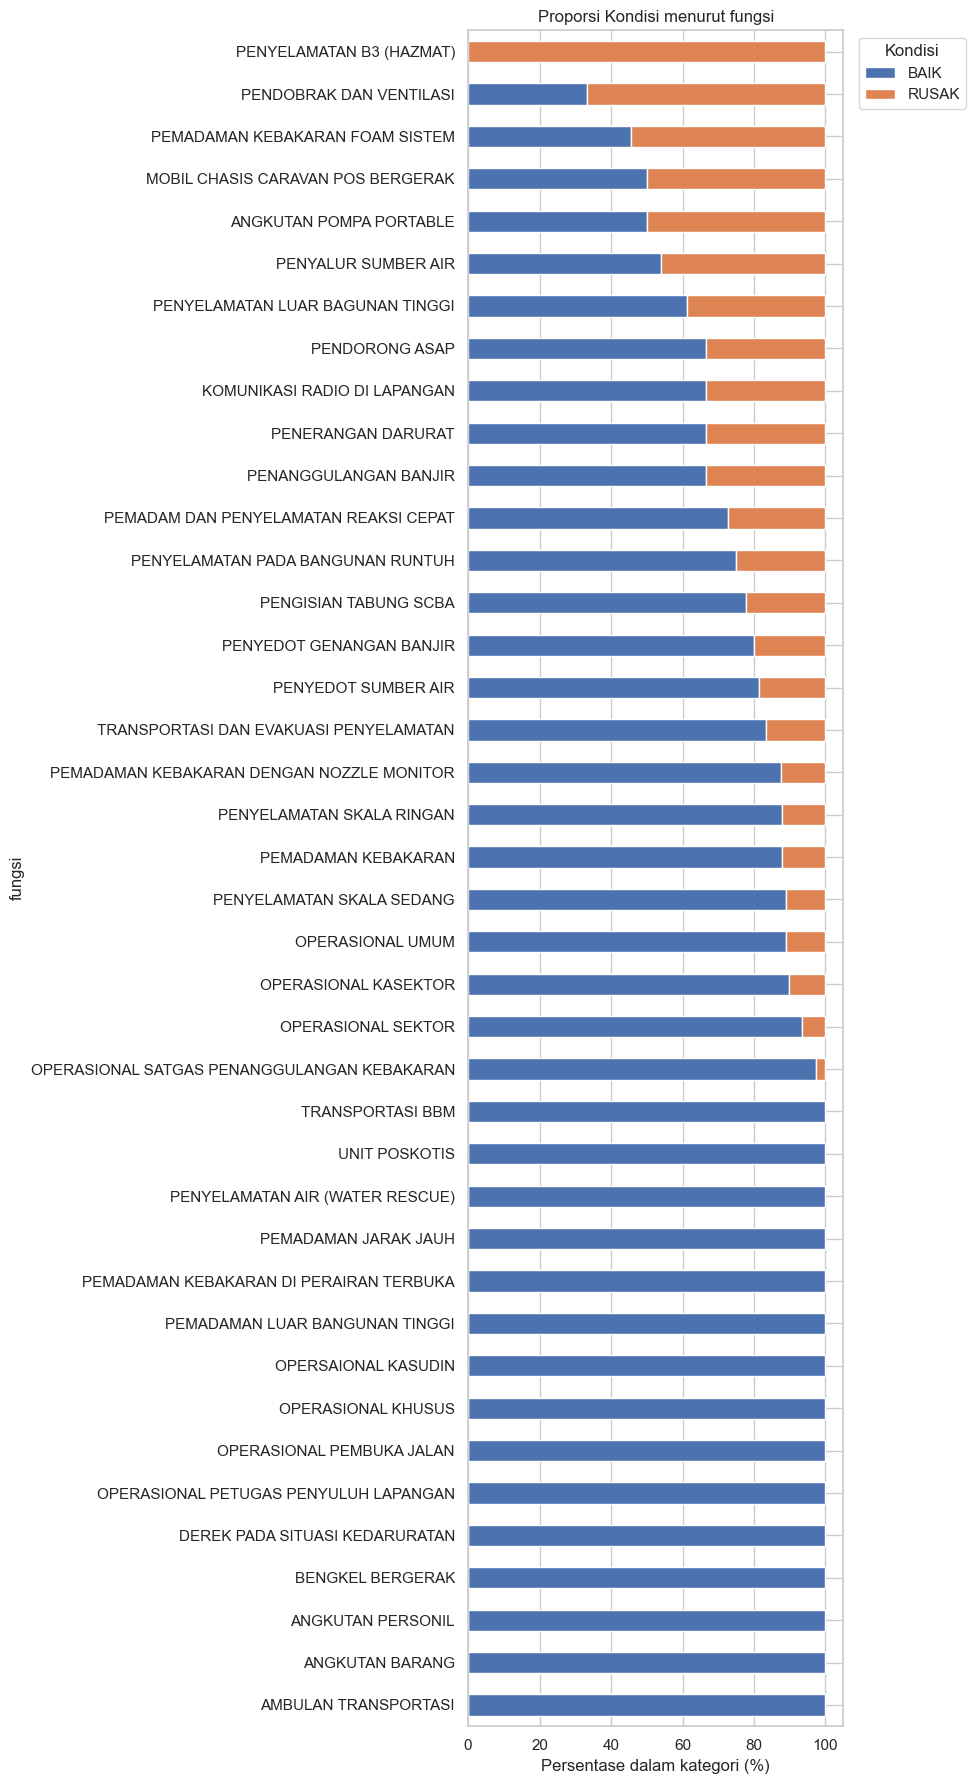

In [39]:
for feature, filename in [("jenis_kendaraan", "04_kondisi_jenis.png"), ("klasifikasi", "05_kondisi_klasifikasi.png"), ("fungsi", "06_kondisi_fungsi.png")]:
    tab = pd.crosstab(df_source[feature], df_source["Kondisi"], normalize="index").mul(100)
    if "RUSAK" in tab.columns:
        tab = tab.sort_values("RUSAK", ascending=True)
    display(tab.round(2))
    ax = tab.plot(kind="barh", stacked=True, figsize=(10, max(4, 0.45 * len(tab))))
    ax.set(title=f"Proporsi Kondisi menurut {feature}", xlabel="Persentase dalam kategori (%)", ylabel=feature)
    ax.legend(title="Kondisi", bbox_to_anchor=(1.02, 1), loc="upper left")
    plt.tight_layout(); plt.savefig(FIGURE_DIR / filename, dpi=160, bbox_inches="tight"); plt.show()

**Interpretasi:** tabel dan grafik dapat digunakan untuk melihat kategori yang memiliki persentase `RUSAK` relatif tinggi atau rendah. Namun, persentase perlu dilihat bersama jumlah kendaraan pada kategori tersebut. Perbedaan yang terlihat hanya menunjukkan pola dalam data dan tidak dapat dijadikan bukti bahwa jenis, fungsi, atau wilayah tertentu menjadi penyebab kerusakan.


## 3.5 Tiga temuan utama dari EDA

Selanjutnya dihitung tiga ringkasan yang mewakili pola penting dalam dataset. Angka ditarik langsung dari data agar uraian yang disampaikan sesuai dengan hasil perhitungan. Kategori dengan jumlah catatan kecil tetap perlu diperhatikan ketika menafsirkan persentasenya.


In [40]:
# Insight 1: kelas target dominan
majority_label = condition_counts.idxmax()
majority_share = float(condition_pct.loc[majority_label])
print(f"Insight 1 — Kelas terbanyak adalah {majority_label}: {int(condition_counts.loc[majority_label])} catatan ({majority_share:.2f}%).")

# Insight 2: wilayah dengan proporsi RUSAK tertinggi, disertai jumlah observasi
wilayah_stats = df_source.groupby("wilayah").agg(
    jumlah_unit=("Kondisi", "size"),
    jumlah_rusak=("Kondisi", lambda s: (s == "RUSAK").sum())
)
wilayah_stats["persen_rusak"] = wilayah_stats["jumlah_rusak"] / wilayah_stats["jumlah_unit"] * 100
wilayah_stats = wilayah_stats.sort_values("persen_rusak", ascending=False)
display(wilayah_stats.round(2))
print("Insight 2 — Wilayah dengan proporsi RUSAK tertinggi:", wilayah_stats.index[0],
      f"({wilayah_stats.iloc[0]['jumlah_rusak']:.0f}/{wilayah_stats.iloc[0]['jumlah_unit']:.0f}; {wilayah_stats.iloc[0]['persen_rusak']:.2f}%).")

# Insight 3: kategori jenis kendaraan dengan proporsi RUSAK tertinggi; jumlah ditampilkan
jenis_stats = df_source.groupby("jenis_kendaraan").agg(
    jumlah_unit=("Kondisi", "size"),
    jumlah_rusak=("Kondisi", lambda s: (s == "RUSAK").sum())
)
jenis_stats["persen_rusak"] = jenis_stats["jumlah_rusak"] / jenis_stats["jumlah_unit"] * 100
jenis_stats = jenis_stats.sort_values("persen_rusak", ascending=False)
display(jenis_stats.round(2))
print("Insight 3 — Jenis kendaraan dengan proporsi RUSAK tertinggi:", jenis_stats.index[0],
      f"({jenis_stats.iloc[0]['jumlah_rusak']:.0f}/{jenis_stats.iloc[0]['jumlah_unit']:.0f}; {jenis_stats.iloc[0]['persen_rusak']:.2f}%).")

Insight 1 — Kelas terbanyak adalah BAIK: 984 catatan (85.34%).


,jumlah_unit,jumlah_rusak,persen_rusak
wilayah,,,
KOTA ADM. JAKARTA TIMUR,250,56,22.40
KOTA ADM. JAKARTA UTARA,195,34,17.44
KOTA ADM. JAKARTA PUSAT,226,35,15.49
KOTA ADM. JAKARTA BARAT,221,26,11.76
KOTA ADM. JAKARTA SELATAN,249,18,7.23
KAB. ADM. KEP. SERIBU,12,0,0.00


Insight 2 — Wilayah dengan proporsi RUSAK tertinggi: KOTA ADM. JAKARTA TIMUR (56/250; 22.40%).


,jumlah_unit,jumlah_rusak,persen_rusak
jenis_kendaraan,,,
MOBIL PENANGANAN BAHAN BERBAHAYA DAN BERACUN (B3),2,2,100.00
MOBIL PENERANGAN PEMADAM KEBAKARAN,5,4,80.00
MOBIL PEMADAM KEBAKARAN BUSA,8,6,75.00
MOBIL PENDOBRAK,3,2,66.67
MOBIL PEMADAM KEBAKARAN BUSA BERTEKANAN TINGGI,3,2,66.67
MOBIL PEMADAM REAKSI CEPAT,8,5,62.50
MOBIL SELANG KEBAKARAN,35,21,60.00
MOBIL KOMUNIKASI OPERASI,2,1,50.00
MOBIL TANGGA,18,6,33.33


Insight 3 — Jenis kendaraan dengan proporsi RUSAK tertinggi: MOBIL PENANGANAN BAHAN BERBAHAYA DAN BERACUN (B3) (2/2; 100.00%).


**Catatan:** temuan pada bagian ini menggambarkan keadaan yang tercatat di dalam dataset dan tidak menjelaskan hubungan sebab-akibat. Pada kelompok dengan jumlah kendaraan sedikit, perubahan satu atau dua catatan saja dapat mengubah persentase secara cukup besar.


# BAGIAN 4 — DATA CLEANING DAN PREPROCESSING

## 4.1 Pemeriksaan kualitas data awal

Pemeriksaan awal dilakukan untuk mengetahui nilai kosong, baris yang sama persis, dan kondisi setiap kolom. Pada salinan sumber lengkap terdapat lima nilai kosong di `plat_nomor`, sedangkan baris duplikat identik tidak ditemukan. Kolom `plat_nomor` kemudian dikeluarkan dari berkas analisis karena merupakan pengenal kendaraan.

Setelah kolom tersebut dihilangkan, terdapat 374 baris yang memiliki nilai sama pada sembilan kolom tersisa. Baris-baris ini tetap dipertahankan. Kesamaan atribut yang terlihat belum cukup untuk memastikan bahwa catatan tersebut berasal dari kendaraan yang sama; bisa saja kendaraan berbeda memiliki jenis, fungsi, lokasi, dan kondisi yang serupa.


In [41]:
source_missing = source_audit.get("source_missing_by_column", {})
source_quality = pd.DataFrame({
    "missing_sumber_asli": pd.Series(source_missing),
    "keterangan": ["Identifier dihapus pada CSV sanitasi" if c == "plat_nomor" else "Tidak ada missing pada audit sumber" for c in source_missing]
})
display(source_quality)
print("Duplikat identik pada sumber lengkap:", source_audit.get("source_exact_duplicate_rows", "tidak tersedia"))
print("Duplikat profil pada CSV setelah plat_nomor dihapus:", int(df_source.duplicated().sum()))
print("Missing pada CSV sanitasi:")
display(df_source.isna().sum().to_frame("jumlah_missing"))

,missing_sumber_asli,keterangan
periode_data,0,Tidak ada missing pada audit sumber
wilayah,0,Tidak ada missing pada audit sumber
kecamatan,0,Tidak ada missing pada audit sumber
kelurahan,0,Tidak ada missing pada audit sumber
jenis_kendaraan,0,Tidak ada missing pada audit sumber
klasifikasi,0,Tidak ada missing pada audit sumber
fungsi,0,Tidak ada missing pada audit sumber
plat_nomor,5,Identifier dihapus pada CSV sanitasi
penempatan,0,Tidak ada missing pada audit sumber
Kondisi,0,Tidak ada missing pada audit sumber


Duplikat identik pada sumber lengkap: 0
Duplikat profil pada CSV setelah plat_nomor dihapus: 374
Missing pada CSV sanitasi:


,jumlah_missing
periode_data,0
wilayah,0
kecamatan,0
kelurahan,0
jenis_kendaraan,0
klasifikasi,0
fungsi,0
penempatan,0
Kondisi,0


## 4.2 Langkah pembersihan data

1. Menghapus spasi yang tidak diperlukan pada awal dan akhir teks.
2. Mengubah teks kosong menjadi nilai yang dikenali sebagai missing value.
3. Menyeragamkan penulisan label pada kolom `Kondisi` menjadi huruf kapital.
4. Mempertahankan baris dengan profil atribut yang sama setelah `plat_nomor` dihilangkan, karena identitas kendaraannya tidak lagi dapat dibedakan dari kolom yang tersisa.
5. Tidak mengisi nilai target yang kosong. Catatan tanpa label kondisi tidak dapat dipakai untuk melatih model terawasi. Nilai kosong pada fitur kategorikal ditangani menggunakan kategori yang paling sering muncul, dengan proses penghitungan dilakukan dari data latih.

Urutan pembersihan dan pengolahan ini menjaga agar informasi dari data uji tidak ikut digunakan ketika model mempelajari data.


In [42]:
df_clean = df_source.copy()
rows_before = len(df_clean)
missing_before = int(df_clean.isna().sum().sum())
profile_duplicates_before = int(df_clean.duplicated().sum())

for col in df_clean.select_dtypes(include=["object", "string"]).columns:
    df_clean[col] = df_clean[col].astype("string").str.strip()
    df_clean[col] = df_clean[col].replace("", pd.NA)

df_clean["Kondisi"] = df_clean["Kondisi"].str.upper()
# Tidak drop_duplicates: duplikasi profil bukan bukti bahwa kendaraan yang dicatat sama.
rows_after = len(df_clean)
missing_after = int(df_clean.isna().sum().sum())
profile_duplicates_after = int(df_clean.duplicated().sum())

before_after = pd.DataFrame([
    {"tahap": "Sebelum cleaning CSV sanitasi", "baris": rows_before, "missing_total": missing_before, "profil_identik": profile_duplicates_before},
    {"tahap": "Sesudah cleaning CSV sanitasi", "baris": rows_after, "missing_total": missing_after, "profil_identik": profile_duplicates_after},
])
display(before_after)
print("Missing per kolom setelah cleaning:")
display(df_clean.isna().sum().to_frame("missing_setelah_cleaning"))
before_after.to_csv(OUTPUT_DIR / "audit_before_after.csv", index=False)
df_clean.to_csv(OUTPUT_DIR / "dataset_cleaned.csv", index=False)

,tahap,baris,missing_total,profil_identik
0,Sebelum cleaning CSV sanitasi,1153,0,374
1,Sesudah cleaning CSV sanitasi,1153,0,374


Missing per kolom setelah cleaning:


,missing_setelah_cleaning
periode_data,0
wilayah,0
kecamatan,0
kelurahan,0
jenis_kendaraan,0
klasifikasi,0
fungsi,0
penempatan,0
Kondisi,0


## 4.3 Hasil pembersihan data

Jumlah baris tidak dikurangi hanya karena beberapa catatan tampak sama setelah proses sanitasi. Tanpa kolom pengenal, tidak ada dasar yang cukup untuk menyimpulkan bahwa catatan tersebut merupakan duplikasi kendaraan yang sama. Lima nilai kosong yang ditemukan pada sumber berada di kolom `plat_nomor`; kolom itu sudah dikeluarkan dari CSV analisis. Dengan demikian, tidak adanya missing value pada kolom CSV sanitasi tidak berarti berkas sumber awal bebas dari nilai kosong.


# BAGIAN 5 — FEATURE SELECTION DAN MODELLING

## 5.1 Pemilihan fitur dan target

Kolom `Kondisi` ditetapkan sebagai target yang akan diprediksi. `periode_data` tidak digunakan karena hanya berisi satu periode. Sementara itu, `kecamatan`, `kelurahan`, dan `penempatan` tidak dimasukkan ke model utama karena merupakan rincian lokasi yang memiliki banyak kategori dan saling bertingkat. Penggunaannya berpotensi membuat model terlalu bergantung pada lokasi tertentu.

Empat fitur yang digunakan adalah `wilayah`, `jenis_kendaraan`, `klasifikasi`, dan `fungsi`. Keempatnya dipilih untuk mewakili wilayah serta karakteristik kendaraan. Karena nilainya berbentuk kategori tanpa urutan, fitur diubah menggunakan One-Hot Encoding agar setiap kategori direpresentasikan sebagai kolom biner.


In [43]:
TARGET = "Kondisi"
FEATURES = ["wilayah", "jenis_kendaraan", "klasifikasi", "fungsi"]
model_df = df_clean.dropna(subset=[TARGET]).copy()
model_df = model_df[model_df[TARGET].isin(["BAIK", "RUSAK"])].copy()
X = model_df[FEATURES].copy()
y = model_df[TARGET].astype(str)

feature_selection_table = pd.DataFrame({
    "fitur": ["wilayah", "kecamatan", "kelurahan", "jenis_kendaraan", "klasifikasi", "fungsi", "penempatan", "periode_data", "plat_nomor"],
    "keputusan": ["Dipakai", "Tidak dipakai", "Tidak dipakai", "Dipakai", "Dipakai", "Dipakai", "Tidak dipakai", "Tidak dipakai", "Dihapus saat sanitasi"],
    "alasan": [
        "Konteks wilayah administratif dengan kategori terbatas",
        "Rincian wilayah berhierarki; redundan dengan wilayah/kelurahan",
        "Rincian lokasi dengan kategori lebih banyak",
        "Karakteristik utama tipe armada",
        "Pengelompokan/kelas kendaraan",
        "Menggambarkan fungsi kendaraan yang tercatat",
        "Kategori lokasi penempatan berpotensi sangat spesifik dan menghafal lokasi",
        "Konstan pada snapshot 2025 sehingga tidak informatif",
        "Identifier kendaraan; bukan atribut umum untuk generalisasi"
    ]
})
display(feature_selection_table)
print("Jumlah data untuk modelling:", len(model_df))
print("Distribusi target:")
display(y.value_counts().to_frame("jumlah"))

,fitur,keputusan,alasan
0,wilayah,Dipakai,Konteks wilayah administratif dengan kategori ...
1,kecamatan,Tidak dipakai,Rincian wilayah berhierarki; redundan dengan w...
2,kelurahan,Tidak dipakai,Rincian lokasi dengan kategori lebih banyak
3,jenis_kendaraan,Dipakai,Karakteristik utama tipe armada
4,klasifikasi,Dipakai,Pengelompokan/kelas kendaraan
5,fungsi,Dipakai,Menggambarkan fungsi kendaraan yang tercatat
6,penempatan,Tidak dipakai,Kategori lokasi penempatan berpotensi sangat s...
7,periode_data,Tidak dipakai,Konstan pada snapshot 2025 sehingga tidak info...
8,plat_nomor,Dihapus saat sanitasi,Identifier kendaraan; bukan atribut umum untuk...


Jumlah data untuk modelling: 1153
Distribusi target:


,jumlah
Kondisi,
BAIK,984
RUSAK,169


## 5.2 Pembagian data latih dan data uji

Dataset dibagi menjadi 80% data latih dan 20% data uji. Nilai `random_state=42` digunakan agar pembagian dapat diulang, sedangkan `stratify=y` menjaga agar perbandingan kelas `BAIK` dan `RUSAK` relatif sama pada kedua bagian. Data uji disimpan untuk mengukur kemampuan model pada catatan yang tidak ikut digunakan selama proses pelatihan.


In [44]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)
print("Ukuran data latih:", X_train.shape)
print("Ukuran data uji:", X_test.shape)
print("Proporsi kelas data latih (%):")
display(y_train.value_counts(normalize=True).mul(100).round(2).to_frame("persentase"))
print("Proporsi kelas data uji (%):")
display(y_test.value_counts(normalize=True).mul(100).round(2).to_frame("persentase"))

Ukuran data latih: (922, 4)
Ukuran data uji: (231, 4)
Proporsi kelas data latih (%):


,persentase
Kondisi,
BAIK,85.36
RUSAK,14.64


Proporsi kelas data uji (%):


,persentase
Kondisi,
BAIK,85.28
RUSAK,14.72


## 5.3 Pengolahan fitur dan model SVM

SVM digunakan sebagai model pembanding. Sebelum pelatihan, nilai kosong pada fitur kategorikal ditangani dengan modus, kemudian setiap kategori diubah menjadi representasi One-Hot. Hasil encoding selanjutnya distandarisasi menggunakan `StandardScaler(with_mean=False)` agar format sparse tetap dapat digunakan. Seluruh tahapan dirangkai dalam `Pipeline`, sehingga proses pengolahan dipelajari dari data latih dan diterapkan dengan cara yang sama pada data uji.


In [45]:
svm_preprocessor = ColumnTransformer(transformers=[
    ("categorical", Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore")),
        ("scaler", StandardScaler(with_mean=False))
    ]), FEATURES)
])
svm_model = Pipeline(steps=[
    ("preprocessing", svm_preprocessor),
    ("svm", SVC(kernel="linear"))
])
svm_model.fit(X_train, y_train)
svm_pred = svm_model.predict(X_test)
print("SVM kernel linear selesai dilatih.")

SVM kernel linear selesai dilatih.


## 5.4 Model utama Random Forest

Random Forest dibangun menggunakan kumpulan pohon keputusan. Beberapa pengaturan yang diuji mencakup jumlah pohon (`n_estimators`) dan kedalaman maksimum (`max_depth`). Konfigurasi akhir menggunakan 100 pohon, kedalaman maksimum 10, kriteria pemisahan Gini, dan `random_state=42`.

Jumlah label `BAIK` dan `RUSAK` tidak seimbang. Untuk mengurangi kecenderungan model mengutamakan kelas mayoritas, konfigurasi akhir memakai `class_weight='balanced'`, sehingga kelas dengan jumlah lebih sedikit memperoleh bobot lebih besar saat proses pembelajaran. Fitur kategorikal tetap diubah menjadi One-Hot, tetapi tidak memerlukan scaling seperti pada SVM karena pemisahan pada pohon keputusan tidak didasarkan pada jarak antarobservasi.


In [46]:
rf_preprocessor = ColumnTransformer(transformers=[
    ("categorical", Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ]), FEATURES)
])
rf_model = Pipeline(steps=[
    ("preprocessing", rf_preprocessor),
    ("random_forest", RandomForestClassifier(
        n_estimators=100,
        max_depth=10,
        criterion="gini",
        class_weight="balanced",
        random_state=RANDOM_STATE
    ))
])
rf_model.fit(X_train, y_train)
rf_pred = rf_model.predict(X_test)
print("Random Forest selesai dilatih.")

Random Forest selesai dilatih.


# BAGIAN 6 — EVALUATION

## 6.1 Perbandingan kinerja model

Random Forest dan SVM dinilai menggunakan bagian data uji yang sama. Accuracy ditampilkan bersama macro-F1, precision, recall, dan F1-score untuk kelas `RUSAK`. Dengan melihat beberapa ukuran sekaligus, penilaian tidak hanya bergantung pada jumlah prediksi benar secara keseluruhan, tetapi juga memperhatikan kemampuan model mengenali kelas yang lebih sedikit.


In [47]:
def evaluate_model(name, y_true, y_pred):
    return {
        "model": name,
        "accuracy": accuracy_score(y_true, y_pred),
        "precision_macro": precision_score(y_true, y_pred, average="macro", zero_division=0),
        "recall_macro": recall_score(y_true, y_pred, average="macro", zero_division=0),
        "macro_f1": f1_score(y_true, y_pred, average="macro", zero_division=0),
        "precision_RUSAK": precision_score(y_true, y_pred, pos_label="RUSAK", zero_division=0),
        "recall_RUSAK": recall_score(y_true, y_pred, pos_label="RUSAK", zero_division=0),
        "f1_RUSAK": f1_score(y_true, y_pred, pos_label="RUSAK", zero_division=0),
    }

comparison = pd.DataFrame([
    evaluate_model("SVM Linear", y_test, svm_pred),
    evaluate_model("Random Forest", y_test, rf_pred),
]).set_index("model")
display(comparison.round(4))
print("\nClassification Report — SVM Linear")
print(classification_report(y_test, svm_pred, labels=["BAIK", "RUSAK"], zero_division=0))
print("\nClassification Report — Random Forest")
print(classification_report(y_test, rf_pred, labels=["BAIK", "RUSAK"], zero_division=0))
comparison.to_csv(OUTPUT_DIR / "model_comparison.csv")

,accuracy,precision_macro,recall_macro,macro_f1,precision_RUSAK,recall_RUSAK,f1_RUSAK
model,,,,,,,
SVM Linear,0.8788,0.7817,0.6612,0.6966,0.6667,0.3529,0.4615
Random Forest,0.8139,0.6738,0.7448,0.6955,0.4151,0.6471,0.5057



Classification Report — SVM Linear
              precision    recall  f1-score   support

        BAIK       0.90      0.97      0.93       197
       RUSAK       0.67      0.35      0.46        34

    accuracy                           0.88       231
   macro avg       0.78      0.66      0.70       231
weighted avg       0.86      0.88      0.86       231


Classification Report — Random Forest
              precision    recall  f1-score   support

        BAIK       0.93      0.84      0.89       197
       RUSAK       0.42      0.65      0.51        34

    accuracy                           0.81       231
   macro avg       0.67      0.74      0.70       231
weighted avg       0.86      0.81      0.83       231



## 6.2 Confusion matrix

Pada confusion matrix, baris menunjukkan label sebenarnya, sedangkan kolom menunjukkan label hasil prediksi. Perhatian khusus diberikan pada catatan yang sebenarnya berlabel `RUSAK` tetapi diprediksi sebagai `BAIK`. Kesalahan ini disebut false negative untuk kelas `RUSAK`, yaitu catatan rusak yang tidak berhasil dikenali model.


## 6.3 Menentukan model yang lebih sesuai

Perbandingan model mempertimbangkan macro-F1 dan recall kelas `RUSAK`, selain accuracy. Macro-F1 memperlakukan kedua kelas secara setara, sedangkan recall `RUSAK` menunjukkan seberapa banyak catatan rusak yang berhasil ditemukan. Jika nilai beberapa metrik berdekatan, hasil perlu ditafsirkan dengan mempertimbangkan jumlah data dan fakta bahwa evaluasi dilakukan melalui satu kali pembagian data latih-uji.


## 6.4 Feature importance Random Forest

Random Forest menyediakan nilai `feature_importances_` untuk menunjukkan kontribusi relatif fitur dalam proses pemisahan kelas pada pohon-pohon yang dibentuk. Karena fitur kategorikal telah diubah menjadi beberapa kolom One-Hot, nilai dari kategori-kategori yang berasal dari satu atribut dijumlahkan kembali. Dengan cara ini, tingkat kepentingan setiap fitur asal dapat dibandingkan dengan lebih mudah.


**Interpretasi feature importance:** nilai yang lebih besar menunjukkan bahwa fitur tersebut lebih banyak berperan dalam pemisahan kelas pada model Random Forest. Angka ini tidak membuktikan hubungan sebab-akibat dan tidak berarti fitur tersebut menjadi penyebab kondisi kendaraan. Banyaknya kategori serta keterkaitan antarfitur juga dapat memengaruhi pembagian nilai importance.


# BAGIAN 7 — CONCLUSION

## 7.1 Jawaban atas pertanyaan analisis

Rangkuman pada bagian ini disusun dari hasil perhitungan yang diperoleh ketika notebook dijalankan. Dengan demikian, angka dan temuan yang ditampilkan merujuk pada dataset serta hasil evaluasi model dalam proyek ini.


## 7.2 Hasil

- Perbandingan label `BAIK` dan `RUSAK` menunjukkan kondisi yang tercatat pada data periode 2025, bukan keadaan kendaraan secara langsung saat ini.
- Recall `RUSAK` menggambarkan bagian catatan berlabel `RUSAK` yang berhasil ditemukan model. Nilai yang rendah berarti masih banyak catatan pada kelas tersebut yang diprediksi sebagai `BAIK`.
- Precision `RUSAK` menunjukkan ketepatan prediksi model ketika memberikan label `RUSAK`. Jika nilainya rendah, sebagian prediksi tersebut ternyata memiliki label `BAIK` pada data uji.
- Model sebaiknya digunakan untuk membantu memahami pola dalam data, bukan sebagai dasar tunggal untuk menentukan penugasan atau kondisi teknis kendaraan.




## 7.3 Keterbatasan

1. Data yang dianalisis hanya mencakup satu periode, yaitu tahun 2025, sehingga perubahan kondisi dari waktu ke waktu belum dapat diamati.
2. Berkas yang digunakan tidak menjelaskan secara rinci kriteria penetapan label `BAIK` dan `RUSAK`, tanggal pemeriksaan, maupun prosedur inspeksinya.
3. Kolom pengenal kendaraan dihilangkan dari berkas analisis. Karena itu, sejumlah baris dengan atribut yang sama tidak dapat dipastikan sebagai kendaraan yang sama atau berbeda.
4. Fitur model hanya mencakup wilayah, jenis kendaraan, klasifikasi, dan fungsi. Informasi usia, intensitas penggunaan, perawatan, serta tingkat kerusakan belum tersedia.
5. Evaluasi dilakukan dengan satu pembagian data latih dan data uji. Pengujian pada data dari periode lain masih diperlukan untuk mengetahui apakah hasilnya dapat diterapkan secara lebih luas.
6. Lisensi dataset bersifat **Terbuka** dan telah berhasil diverifikasi melalui metadata dataset yang dapat diakses. Halaman umum Satu Data Jakarta menyatakan bahwa data pada portal dapat dimanfaatkan dan digunakan kembali. Atribusi sumber tetap dicantumkan.
7. Hasil klasifikasi hanya berkaitan dengan label pada dataset dan tidak menjelaskan penyebab kerusakan maupun kesiapan kendaraan secara real-time.

## 7.4 Kesimpulan akhir

Analisis ini memberikan gambaran mengenai data kendaraan operasional pemadam kebakaran dan penyelamatan DKI Jakarta periode 2025 melalui EDA dan klasifikasi. Random Forest digunakan sebagai model utama, sedangkan SVM kernel linear menjadi pembanding. Penilaian dilakukan dengan melihat confusion matrix, classification report, macro-F1, serta precision dan recall untuk kelas `RUSAK`.

Hasil pengujian menunjukkan bahwa setiap model memiliki keunggulan pada ukuran evaluasi yang berbeda. Oleh karena itu, pemilihan model perlu disesuaikan dengan tujuan penggunaan dan tidak cukup didasarkan pada accuracy saja. Seluruh temuan tetap terbatas pada informasi yang tersedia di dataset dan tidak menggantikan pemeriksaan langsung terhadap kendaraan.
